Does a mothers education predict adult earnings after accounting for family income?
1)  Run a multiple linear regression including mother income rank and parental education.
2) Include sex and race/ethnicity as control variables where available.
3) Report regression coefficients, confidence intervals, and p-values.
4) Create one polished visualization comparing adjusted associations (`figures/finding-two.png`).


R1302400	Biological father's highest grade completed	Predictor
R1302500	Biological mother's highest grade completed	Predictor
CV_INCOME_FAMILY	Respondent's total family income	Control variable
Adult earnings	Respondent's own earnings as an adult	Outcome

In [1]:
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# Load NLSY97 dataset
nlsy97 = pl.read_csv("data/raw/nlsy97/NLSY97_expanded.csv")

print("Dataset shape:", nlsy97.shape)
print("\nColumns:")
print(nlsy97.columns)

Dataset shape: (8984, 12)

Columns:
['R0000100', 'R0536300', 'R0536401', 'R0536402', 'R1204500', 'R1235800', 'R1302400', 'R1302500', 'R1482600', 'U5753300', 'U5753500', 'Z9061911']


In [2]:

# Preview the dataset
print(nlsy97.head(10))

# Check each column's data type and missing values
print("\nColumn information:")
print(nlsy97.schema)

# Summary statistics
print("\nSummary statistics:")
print(nlsy97.describe())

shape: (10, 12)
┌──────────┬──────────┬──────────┬──────────┬───┬──────────┬──────────┬──────────┬──────────┐
│ R0000100 ┆ R0536300 ┆ R0536401 ┆ R0536402 ┆ … ┆ R1482600 ┆ U5753300 ┆ U5753500 ┆ Z9061911 │
│ ---      ┆ ---      ┆ ---      ┆ ---      ┆   ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ i64      ┆ i64      ┆ i64      ┆ i64      ┆   ┆ i64      ┆ i64      ┆ i64      ┆ i64      │
╞══════════╪══════════╪══════════╪══════════╪═══╪══════════╪══════════╪══════════╪══════════╡
│ 1        ┆ 2        ┆ 9        ┆ 1981     ┆ … ┆ 4        ┆ -5       ┆ -5       ┆ 0        │
│ 2        ┆ 1        ┆ 7        ┆ 1982     ┆ … ┆ 2        ┆ 1        ┆ 115000   ┆ 52       │
│ 3        ┆ 2        ┆ 9        ┆ 1983     ┆ … ┆ 2        ┆ 0        ┆ -4       ┆ 0        │
│ 4        ┆ 2        ┆ 2        ┆ 1981     ┆ … ┆ 2        ┆ 1        ┆ 45000    ┆ 52       │
│ 5        ┆ 1        ┆ 10       ┆ 1982     ┆ … ┆ 2        ┆ 1        ┆ 150000   ┆ 52       │
│ 6        ┆ 2        ┆ 1        ┆ 1982     

In [8]:

# Convert to pandas for statsmodels regression
df = nlsy97.to_pandas()

# Replace NLSY97 special missing-value codes
missing_codes = [-1, -2, -3, -4, -5]

for col in ["R1204500", "U5753500", "U5753300",
            "R1302400", "R1302500"]:
    df[col] = df[col].replace(missing_codes, np.nan)

# Education code 95 represents an unknown category
for col in ["R1302400", "R1302500"]:
    df[col] = df[col].replace(95, np.nan)

# Respondents who explicitly reported no job income
# are assigned zero wages when wages were skipped
no_income = df["U5753300"] == 0
df.loc[no_income & df["U5753500"].isna(), "U5753500"] = 0

# Keep respondents with valid childhood income
# and positive reported adult wages
analysis_df = df.loc[
    df["R1204500"].notna() &
    (df["U5753500"] > 0)
].copy()

# Create percentile ranks among parent education
analysis_df["father_education_rank"] = (
    analysis_df["R1302400"].rank(pct=True) * 100
)

analysis_df["mother_education_rank"] = (
    analysis_df["R1302500"].rank(pct=True) * 100
)

# Create percentile ranks among the selected earners
analysis_df["gross_family_income_rank"] = (
    analysis_df["R1204500"].rank(pct=True) * 100
)



print("Total respondents:", len(df))
print("Respondents included in regression:", len(analysis_df))
print(analysis_df[
    ["gross_family_income_rank", "father_education_rank", "mother_education_rank"]
].describe())

Total respondents: 8984
Respondents included in regression: 3847
       gross_family_income_rank  father_education_rank  mother_education_rank
count               3847.000000            3230.000000            3660.000000
mean                  50.012997              50.015480              50.013661
std                   28.871017              27.935774              28.133706
min                    0.025994               0.154799               0.027322
25%                   25.110476              39.287926              37.185792
50%                   50.000000              39.287926              37.185792
75%                   74.980504              76.315789              70.614754
max                   99.064206              98.900929              99.453552


In [9]:
# Simple linear regression
model1 = smf.ols(
    "gross_family_income_rank ~ mother_education_rank",
    data=analysis_df
).fit()

# Display regression results
print(model1.summary())

# Extract important statistics
coefficient = model1.params["mother_education_rank"]
p_value = model1.pvalues["mother_education_rank"]
ci_lower, ci_upper = model1.conf_int().loc["mother_education_rank"]
r_squared = model1.rsquared

print("\n--- FINDING 2 RESULTS ---")
print(f"Coefficient: {coefficient:.4f}")
print(f"95% Confidence Interval: [{ci_lower:.4f}, {ci_upper:.4f}]")
print(f"P-value: {p_value:.6g}")
print(f"R-squared: {r_squared:.4f}")
print(f"Sample size: {int(model1.nobs)}")

                               OLS Regression Results                               
Dep. Variable:     gross_family_income_rank   R-squared:                       0.189
Model:                                  OLS   Adj. R-squared:                  0.188
Method:                       Least Squares   F-statistic:                     850.2
Date:                      Sun, 15 Nov 2026   Prob (F-statistic):          3.03e-168
Time:                              20:44:12   Log-Likelihood:                -17103.
No. Observations:                      3660   AIC:                         3.421e+04
Df Residuals:                          3658   BIC:                         3.422e+04
Df Model:                                 1                                         
Covariance Type:                  nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------

In [10]:

# Rename demographic and education columns
adjusted_df = analysis_df.rename(columns={
    "R1302400": "father_education",
    "R1302500": "mother_education",
    "R0536300": "sex",
    "R1482600": "race_ethnicity"
}).copy()

# Keep only respondents with complete data
adjusted_df = adjusted_df.dropna(subset=[
    "gross_family_income_rank",
    "mother_education_rank",
    "father_education",
    "mother_education",
    "sex",
    "race_ethnicity"
])

# Baseline model: Mother's education only
baseline_model = smf.ols(
    "gross_family_income_rank ~ mother_education_rank",
    data=adjusted_df
).fit()

# Adjusted model: Add father's education and demographics
adjusted_model = smf.ols(
    """gross_family_income_rank ~ mother_education_rank
       + C(father_education)
       + C(sex)
       + C(race_ethnicity)""",
    data=adjusted_df
).fit()

# Compare results
for name, model in [
    ("Baseline", baseline_model),
    ("Adjusted", adjusted_model)
]:
    coef = model.params["mother_education_rank"]
    lower, upper = model.conf_int().loc["mother_education_rank"]

    print(f"\n{name}")
    print(f"Sample size: {int(model.nobs)}")
    print(f"Mother's education coefficient: {coef:.4f}")
    print(f"95% CI: [{lower:.4f}, {upper:.4f}]")
    print(f"P-value: {model.pvalues['mother_education_rank']:.4g}")
    print(f"R-squared: {model.rsquared:.4f}")



Baseline
Sample size: 3165
Mother's education coefficient: 0.4340
95% CI: [0.4019, 0.4660]
P-value: 2e-140
R-squared: 0.1823

Adjusted
Sample size: 3165
Mother's education coefficient: 0.2335
95% CI: [0.1966, 0.2704]
P-value: 1.537e-34
R-squared: 0.2999


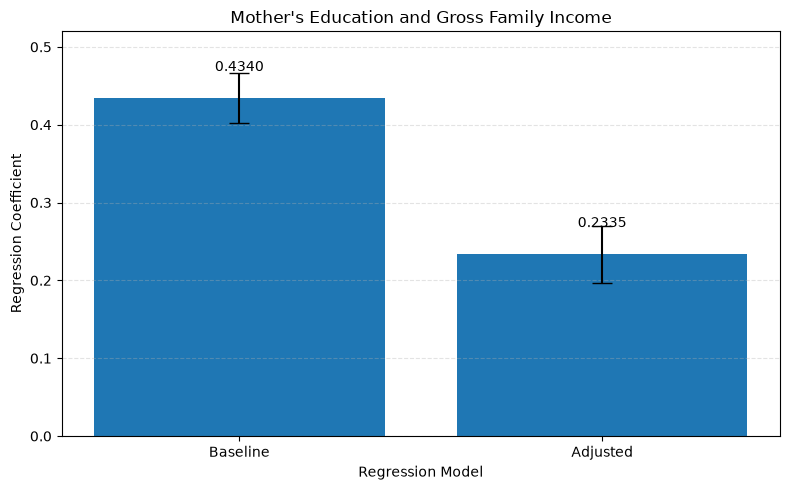

In [11]:
# Regression coefficients
models = ["Baseline", "Adjusted"]
coefficients = [0.4340, 0.2335]

# 95% confidence intervals
ci_lower = [0.4019, 0.1966]
ci_upper = [0.4660, 0.2704]

# Calculate error bar lengths
lower_errors = [
    coefficients[i] - ci_lower[i] for i in range(2)
]
upper_errors = [
    ci_upper[i] - coefficients[i] for i in range(2)
]

# Create bar chart
plt.figure(figsize=(8, 5))

plt.bar(
    models,
    coefficients,
    yerr=[lower_errors, upper_errors],
    capsize=7
)

# Labels and title
plt.title("Mother's Education and Gross Family Income")
plt.xlabel("Regression Model")
plt.ylabel("Regression Coefficient")

# Display coefficient values above bars
for i, value in enumerate(coefficients):
    plt.text(i, value + 0.035, f"{value:.4f}", ha="center")

plt.ylim(0, 0.52)
plt.grid(axis="y", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()